<a href="https://colab.research.google.com/github/SergeiVKalinin/MSE_Fall_2026/blob/main/Module%206/Final_2_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Drift control

An instrument takes images of a sample, one small square at a time. The sample is a 20 x 20 grid of handwritten digits. While it works, the instrument **drifts**: the image comes from a place a little off from where you asked. If the drift gets big, you get the neighbouring digit instead.

At every step your agent picks one of two actions:

| action | number | time it takes | what happens |
|---|---|---|---|
| MEASURE | 0 | 1 | take an image of the current square, then go to the next square |
| CORRECT | 1 | 4 | check how far the instrument has drifted and fix it (no new image) |

One problem lasts **300 time units**. When the time is used up, the problem is over.

**Why drift matters.** Every image is used to train a small neural network, the *learner*. The learner is trained with the digit you asked for. A drifted image shows another digit, so it teaches the learner something wrong. A correction costs time you could spend measuring. Your agent has to find a good balance.

**Score.** At the end the learner is tested on digits it has not seen:

`score = - test loss + 0.5 * (number of measurements) / 300`

Higher is better. The test loss tells how wrong the learner is. The second part pays you for measuring.

**What your agent sees.** After each step it gets a few numbers, the *observation* (listed in section 1). It never sees the drift itself.

**What to do**

1. Sections 1 to 3: see how a problem works and which simple rules you have to beat.
2. Section 4: look at the numbers you will train on.
3. Section 5: write your agent and train it.
4. Section 6: test it on new problems.
5. Section 7: answer the questions.
6. Section 8: run it on the server. This part is graded.

Hand in this notebook with all outputs saved.

In [ ]:
# imports. If drift_sim is missing (for example on Colab), the first lines install it.
try:
    import drift_sim
except ImportError:
    %pip install -q "git+https://github.com/Slautin/2026_Midterm_fall_2.git"
    import drift_sim

import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from drift_sim import BASELINES, DriftEnv, evaluate, play, summary
from matplotlib.lines import Line2D

MEASURE, CORRECT = 0, 1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# helper functions for tables and plots. You do not need to read this cell, just run it.
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 100})


def report(results):
    """Print one line per rule or agent: mean score and return over the problems, and the actions used."""
    print(f"{'':14s} {'score':>15s} {'return':>15s} {'accuracy':>9s} {'measure':>8s} {'correct':>8s}")
    for name, rows in results.items():
        score = np.array([r["hidden_score"] for r in rows])
        ret = np.array([r["local_return"] for r in rows])
        m = summary(rows)
        print(f"{name:14s} {score.mean():8.3f} ±{score.std():5.3f} {ret.mean():8.1f} ±{ret.std():5.1f} "
              f"{m['hidden_test_accuracy']:9.3f} {m['n_measurements']:8.0f} {m['n_corrections']:8.0f}")


def plot_episode(log, title=""):
    """Draw one problem from a log made by play(): actions, learner uncertainty, return, drift found."""
    t = log["time"].to_numpy()
    fix = (log["action"] == 1).to_numpy()
    fig, (acts, unc, ret, reg) = plt.subplots(4, 1, figsize=(9, 7.4), sharex=True,
                                              gridspec_kw={"height_ratios": [1, 2, 2, 2]})
    for x in t[~fix]:
        acts.axvline(x, color="#2a78d6", alpha=0.35, lw=1)
    for x in t[fix]:
        acts.axvspan(x - 4, x, color="#eb6834", alpha=0.7, lw=0)  # a correction takes 4 time units
    acts.set(yticks=[])
    acts.set_title(title, loc="left")
    acts.grid(False)
    acts.legend([Line2D([], [], color="#2a78d6", lw=2), Line2D([], [], color="#eb6834", lw=6)],
                ["measure (1 time unit)", "correct (4 time units)"], loc="lower right", bbox_to_anchor=(1, 1.02),
                ncol=2, frameon=False, fontsize=8)
    unc.plot(t, log["model_uncertainty"], color="#0b0b0b", lw=1.4)
    unc.set(ylabel="model_uncertainty", ylim=(0, None))
    total = log["reward"].sum()
    ret.plot(t, log["reward"].cumsum(), color="#0b0b0b", lw=1.4)
    ret.axhline(0, color="#898781", lw=0.8, ls=":")
    ret.annotate(f"{total:+.1f}", (t[-1], total), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ret.set(ylabel="return so far")
    if fix.any():
        size = np.hypot(log["last_estimated_shift_x"], log["last_estimated_shift_y"]).to_numpy()[fix]
        reg.vlines(t[fix], 0, size, color="#eb6834", lw=1.2)
        reg.plot(t[fix], size, "o", color="#eb6834", ms=4)
        conf = log["registration_confidence"].to_numpy()[fix].astype(float)
        reg.text(0.99, 0.95, f"confidence of the corrections: {conf.min():.2f} to {conf.max():.2f}",
                 transform=reg.transAxes, ha="right", va="top", fontsize=8)
    else:
        reg.text(0.5, 0.5, "no correction in this problem", transform=reg.transAxes, ha="center", va="center", color="#6b6a65")
    reg.set(ylabel="drift found (px)", ylim=(0, None), xlabel="time used", xlim=(0, t[-1] * 1.06))
    fig.align_ylabels()
    fig.tight_layout()
    plt.show()


def plot_learning_curve(returns, window=10):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(returns, color="#2a78d6", alpha=0.3, lw=1, label="one problem")
    if len(returns) >= window:
        ax.plot(np.arange(window - 1, len(returns)), np.convolve(returns, np.ones(window) / window, "valid"),
                color="#0b0b0b", lw=2, label=f"average of {window}")
    ax.set(xlabel="training problem", ylabel="return", title="return during training")
    ax.legend(frameon=False)
    plt.show()


def plot_scores(results):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    rng = np.random.default_rng(0)
    for i, (name, rows) in enumerate(results.items()):
        y = [r["hidden_score"] for r in rows]
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(y)), y, s=14, color="#2a78d6", alpha=0.55, lw=0)
        ax.hlines(np.median(y), i - 0.3, i + 0.3, color="#0b0b0b", lw=2)
    ax.set_xticks(range(len(results)), list(results), rotation=20)
    ax.set(ylabel="score (higher is better)", title="score on the test problems (one dot each, line = median)")
    plt.show()

## 1. One problem, step by step

`DriftEnv(seed=7)` makes one problem. The same seed always gives the same problem. This is the simulator you train on. It works like the one in the graded run.

`env.step(action)` gives back four things: the new observation, the reward, `done` (True when the time is up) and `info` (you can ignore it).

In [ ]:
env = DriftEnv(seed=7)
print("start:", env.observation())

obs, reward, done, info = env.step(MEASURE)
print("\nafter MEASURE: time used =", obs["time"], "| reward =", round(reward, 3))

obs, reward, done, info = env.step(CORRECT)
print("after CORRECT: time used =", obs["time"], "| reward =", reward)
print("the correction found a drift of", (obs["last_estimated_shift_x"], obs["last_estimated_shift_y"]), "pixels")

start: {'schema_version': 1, 'time': 0, 'remaining': 300, 'correction_age': 0, 'n_measurements': 0, 'n_corrections': 0, 'model_uncertainty': 0.4794904589653015, 'has_registration': False, 'registration_confidence': None, 'last_estimated_shift_x': 0.0, 'last_estimated_shift_y': 0.0, 'legal_actions': [0, 1]}

after MEASURE: time used = 1 | reward = 0.179
after CORRECT: time used = 5 | reward = 0.0
the correction found a drift of (-1.0, -2.0) pixels


The observation, field by field:

| name | meaning |
|---|---|
| `time` | time units used so far (0 to 300) |
| `remaining` | time units left |
| `correction_age` | time since the last correction (or since the start) |
| `n_measurements`, `n_corrections` | how many of each so far |
| `model_uncertainty` | how unsure the learner is on a small check set (0 to 1) |
| `has_registration` | True after the first correction |
| `registration_confidence` | how sure the last correction was (None before the first one) |
| `last_estimated_shift_x`, `last_estimated_shift_y` | how far the last correction found the instrument had drifted, in pixels |
| `legal_actions` | the actions you can still afford |

**Reward.** After a measurement: 100 times the drop of the learner's loss on the check set, plus 0.17. The loss can also go up, then the reward is negative. After a correction the reward is always 0. It only pays off later, through better images.

**Return** is the sum of the rewards of one problem. Your agent tries to make it large.

`env.final_metrics()` shows the final test loss, accuracy and score of a local problem. On the server you only get the score.

*More about the drift (you can skip this).* It is a slow straight-line movement plus a wave plus a little random jitter: `d(t) = v*t + A*(sin(2*pi*t/P + phi) - sin(phi))*u + jitter`. `A` is 14 pixels, `v` is below 0.045 pixels per time unit in each direction, the period `P` is between 110 and 170, the jitter is about 2 pixels. The direction `u` and the phase `phi` are hidden. Every problem has its own drift, its own digits and its own order of squares.

## 2. A whole problem

`play(env, agent_function)` plays one problem to the end and keeps every number the environment returned, one row per step. Here a simple rule is used: correct when the last correction is 20 time units old.

The figure shows the same rows:

- top: your actions (blue = measure, orange = correct)
- `model_uncertainty`: how unsure the learner is on the check set
- return so far: the rewards added up
- drift found: how far each correction found the instrument had drifted

,step,action,reward,done,time,remaining,correction_age,n_measurements,n_corrections,model_uncertainty,has_registration,registration_confidence,last_estimated_shift_x,last_estimated_shift_y,legal_actions
0,1,0,0.179345,False,1,299,1,1,0,0.478831,False,NaN,0.0,0.0,"[0, 1]"
1,2,0,-1.963460,False,2,298,2,2,0,0.487332,False,NaN,0.0,0.0,"[0, 1]"
2,3,0,-3.832292,False,3,297,3,3,0,0.499212,False,NaN,0.0,0.0,"[0, 1]"
3,4,0,-5.535513,False,4,296,4,4,0,0.510419,False,NaN,0.0,0.0,"[0, 1]"
4,5,0,-4.298210,False,5,295,5,5,0,0.516185,False,NaN,0.0,0.0,"[0, 1]"


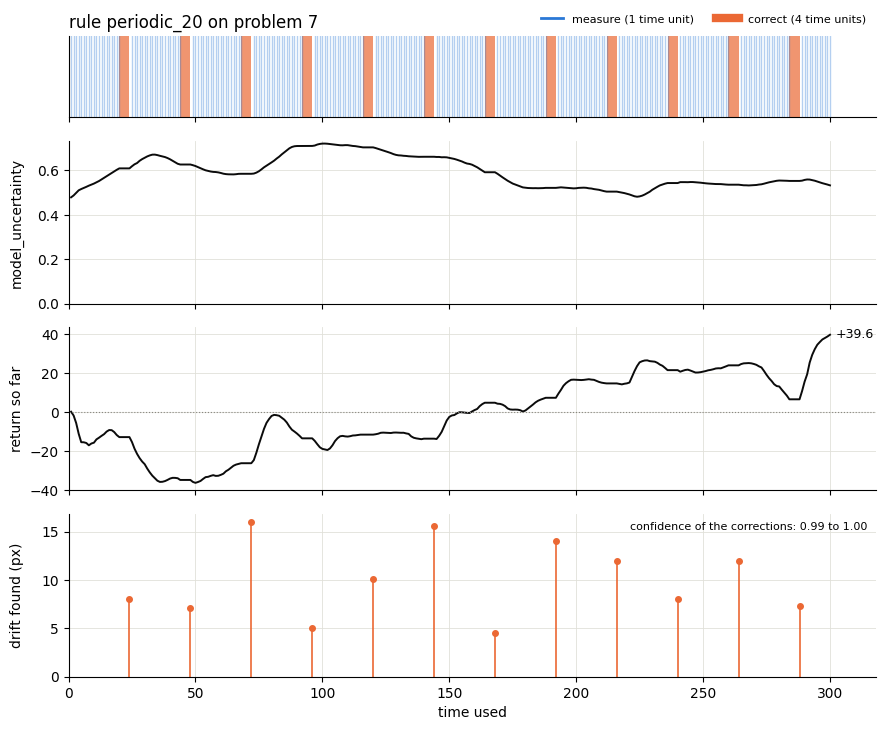

final numbers of this problem: {'hidden_test_loss': 0.3710154592990875, 'hidden_test_accuracy': 0.9449999928474426, 'n_measurements': 252, 'n_corrections': 12, 'hidden_score': 0.04898454070091246, 'local_return': 39.6033717393875}


In [ ]:
env = DriftEnv(seed=7)
log = pd.DataFrame(play(env, BASELINES["periodic_20"]))  # one row per step
display(log.head())
plot_episode(log, "rule periodic_20 on problem 7")
print("final numbers of this problem:", env.final_metrics())

## 3. Simple rules to beat

Five fixed rules, no learning:

- `never`: never correct
- `every`: correct before every measurement
- `periodic_10`, `periodic_20`, `periodic_40`: correct when the last correction is 10, 20 or 40 time units old

The table shows them on 20 test problems (seeds 0 to 19). It takes about 30 seconds. Your agent should do better.

How to read it: `score` is what counts. `return` is the sum of the rewards your agent sees. `accuracy` is the learner's accuracy on the test digits. `measure` and `correct` are the average number of each action per problem.

In [ ]:
EVAL_SEEDS = range(20)  # test problems. Never train on these.
baseline_results = {name: evaluate(rule, EVAL_SEEDS) for name, rule in BASELINES.items()}
report(baseline_results)

                         score          return  accuracy  measure  correct
never            -0.473 ±0.304    -11.4 ± 29.5     0.683      300        0
every            -0.312 ±0.103      3.1 ± 10.1     0.905       60       60
periodic_10      -0.049 ±0.061     29.5 ±  6.1     0.901      216       21
periodic_20      -0.080 ±0.134     26.2 ± 13.2     0.902      252       12
periodic_40      -0.314 ±0.248      4.1 ± 24.1     0.787      276        6


## 4. The numbers you train on

Your agent learns from the observation and the reward of every step. Here are the real values. The next cell plays 20 training problems with a simple rule: 15 % of the time it corrects at random, otherwise it measures.

In [ ]:
random.seed(0)


def explore(obs):
    if CORRECT in obs["legal_actions"] and random.random() < 0.15:
        return CORRECT
    return MEASURE


data = pd.concat([pd.DataFrame(play(DriftEnv(seed=s), explore)) for s in range(100, 120)])
data["shift"] = np.hypot(data["last_estimated_shift_x"], data["last_estimated_shift_y"])  # size of the last shift
print(len(data), "steps from 20 problems\n")

print("the observation:")
fields = ["time", "correction_age", "n_measurements", "n_corrections", "model_uncertainty", "registration_confidence", "shift"]
display(data[fields].describe().loc[["mean", "min", "50%", "max"]].rename(index={"50%": "median"}).round(2).T)

print("the reward:")
display(data.groupby("action")["reward"].describe()[["count", "mean", "std", "min", "50%", "max"]]
        .rename(columns={"50%": "median"}).rename(index={0: "measure", 1: "correct"}).round(2))

4137 steps from 20 problems

the observation:


,mean,min,median,max
time,151.27,1.00,151.00,300.00
correction_age,5.72,0.00,4.00,35.00
n_measurements,88.45,0.00,88.00,200.00
n_corrections,15.70,0.00,16.00,37.00
model_uncertainty,0.57,0.39,0.57,0.77
registration_confidence,0.99,0.98,0.99,1.00
shift,4.13,0.00,3.16,21.95


the reward:


,count,mean,std,min,median,max
action,,,,,,
measure,3516.0,0.12,1.82,-10.68,0.25,8.52
correct,621.0,0.00,0.00,0.00,0.00,0.00


What to notice:

- The reward of a measurement is small on average but jumps around a lot (look at `std`, `min` and `max`). One step tells you little. Judge by whole problems.
- A correction always gets reward 0.
- `registration_confidence` stays close to 1, so it will not help you decide.
- `shift` is how far the last correction moved the instrument. It reaches 10 pixels or more, so it tells you how fast the instrument drifts.

## 5. Your agent

Your agent is a class with three methods:

- `choose_action(obs)` returns 0 (measure) or 1 (correct)
- `update(obs, action, reward, next_obs, done)` learns from one step
- `end_episode()` is called after each training problem (optional)

`agent.training` is True while training and False afterwards. Use it to explore only while training.

The agent below always measures, so it does the same as the rule `never`. Replace it with your own. Fill in two cells:

1. `state_features`: turn the observation into the numbers your agent works with (optional helper, use it inside your agent)
2. `Agent`: your learning method (Q-learning, SARSA, DQN, policy gradient, or anything else)

In [ ]:
# TODO: choose the observation fields your agent needs and turn them into numbers.
def state_features(obs):
    return np.array([obs["correction_age"] / 300, obs["remaining"] / 300])

In [ ]:
# TODO: write your agent. This one always measures.
class Agent:
    def __init__(self):
        self.training = True

    def choose_action(self, obs):
        # obs["legal_actions"] lists the actions you can afford
        return MEASURE

    def update(self, obs, action, reward, next_obs, done):
        pass  # TODO: learn from this step

    def end_episode(self):
        pass  # optional, for example lower the exploration rate

### Train it

`train` plays training problems one after another and calls `update` after every step. At the end it prints a short summary and draws the return of each problem.

How many problems? One problem takes about 0.3 seconds on a laptop (Colab can be slower). Start with 100 to check that your code works. As a rough guide, simple methods need a few hundred problems, neural networks a few thousand.

The training problems here use seeds 100 to 139. You can use any other seeds too, but never seeds 0 to 19, they are for testing. The 40 problems are used again and again, so the curve may repeat every 40 problems.

trained on 100 problems (30000 steps) in 93 seconds
average return: first 10 problems -27.9, last 10 problems -29.6
share of the steps that were corrections: 0%


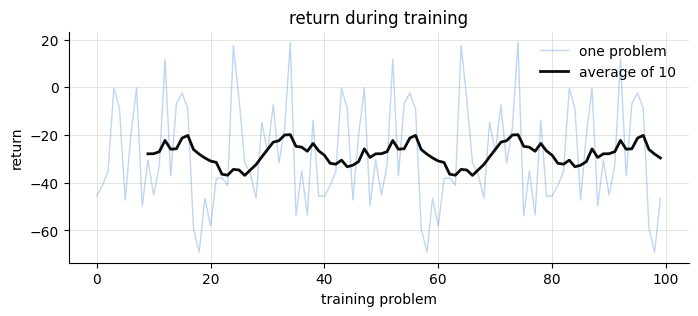

In [ ]:
TRAIN_SEEDS = range(100, 140)  # training problems
N_EPISODES = 100               # TODO: use more for a real run


def train(agent, n_episodes=N_EPISODES):
    agent.training = True
    returns, steps, corrections = [], 0, 0
    start = time.time()
    for episode in range(n_episodes):
        env = DriftEnv(seed=TRAIN_SEEDS[episode % len(TRAIN_SEEDS)])
        obs, total = env.observation(), 0.0
        while not env.done:
            action = agent.choose_action(obs)
            next_obs, reward, done, info = env.step(action)
            agent.update(obs, action, reward, next_obs, done)
            obs, total = next_obs, total + reward
            steps += 1
            corrections += action == CORRECT
        agent.end_episode()
        returns.append(total)
    agent.training = False
    print(f"trained on {n_episodes} problems ({steps} steps) in {time.time() - start:.0f} seconds")
    print(f"average return: first 10 problems {np.mean(returns[:10]):+.1f}, last 10 problems {np.mean(returns[-10:]):+.1f}")
    print(f"share of the steps that were corrections: {corrections / steps:.0%}")
    return returns


agent = Agent()
returns = train(agent)
plot_learning_curve(returns)

## 6. Test it on new problems

Your agent against the simple rules, on the 20 test problems. The table is the same as before. In the plot every dot is one problem.

                         score          return  accuracy  measure  correct
never            -0.473 ±0.304    -11.4 ± 29.5     0.683      300        0
every            -0.312 ±0.103      3.1 ± 10.1     0.905       60       60
periodic_10      -0.049 ±0.061     29.5 ±  6.1     0.901      216       21
periodic_20      -0.080 ±0.134     26.2 ± 13.2     0.902      252       12
periodic_40      -0.314 ±0.248      4.1 ± 24.1     0.787      276        6
my agent         -0.473 ±0.304    -11.4 ± 29.5     0.683      300        0


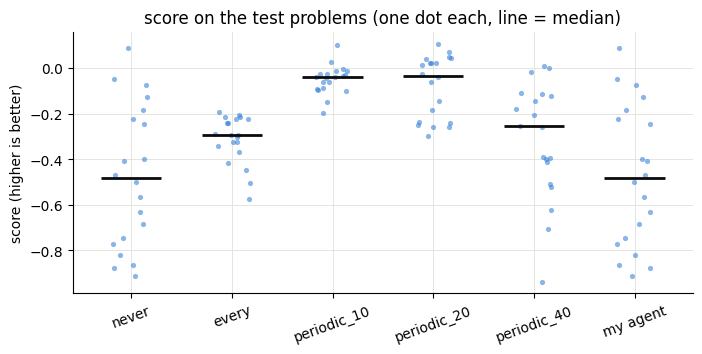

In [ ]:
results = dict(baseline_results)
results["my agent"] = evaluate(agent.choose_action, EVAL_SEEDS)
report(results)
plot_scores(results)

Your agent on problem 7. Does it do what you expected?

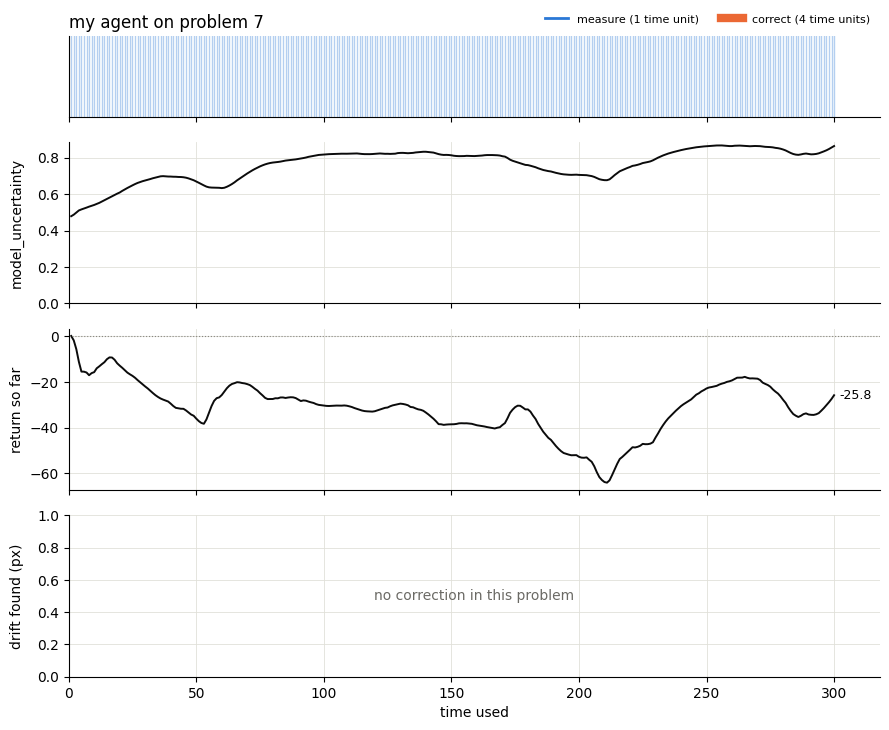

final numbers of this problem: {'hidden_test_loss': 1.129146933555603, 'hidden_test_accuracy': 0.42500001192092896, 'n_measurements': 300, 'n_corrections': 0, 'hidden_score': -0.629146933555603, 'local_return': -25.82521438598646}


In [ ]:
env = DriftEnv(seed=7)
plot_episode(pd.DataFrame(play(env, agent.choose_action)), "my agent on problem 7")
print("final numbers of this problem:", env.final_metrics())

## 7. Questions

Write your answers in the next cell, in your own words. A few sentences for each is enough.

1. What does your agent do? When does it correct? Which numbers of the observation does it use? Use the figure above.
2. How does it compare with the simple rules? Look at the number of measurements and corrections, not only at the score. Be careful with an agent that (almost) never measures. Its return is close to 0 and its score is about -0.33. That looks safe, but it is bad.
3. What would change in the best strategy if
    - a correction took more time,
    - the drift were stronger,
    - the random jitter were larger,
    - the 0.5 in the score were larger or smaller?
4. What would you try next, if you had more time?

**My answers** (double-click here to edit)

1.
2.
3.
4.

## 8. The server and the graded run

The graded problems are on the course server. First check that you can reach it. The next cell plays practice problem 7 on the server and on your computer. The numbers must be the same. Tiny differences in the last digits are normal.

connected to https://drift-server-production-4aed294d.up.railway.app: budget 300 time units per problem, a measurement costs 1, a correction 4, test mode on


,step,action,reward,done,time,remaining,correction_age,n_measurements,n_corrections,model_uncertainty,has_registration,registration_confidence,last_estimated_shift_x,last_estimated_shift_y,legal_actions
0,1,0,0.179348,False,1,299,1,1,0,0.478831,False,NaN,0.0,0.0,"[0, 1]"
1,2,0,-1.963454,False,2,298,2,2,0,0.487332,False,NaN,0.0,0.0,"[0, 1]"
2,3,0,-3.832298,False,3,297,3,3,0,0.499212,False,NaN,0.0,0.0,"[0, 1]"
3,4,0,-5.535501,False,4,296,4,4,0,0.510419,False,NaN,0.0,0.0,"[0, 1]"
4,5,0,-4.298216,False,5,295,5,5,0,0.516185,False,NaN,0.0,0.0,"[0, 1]"


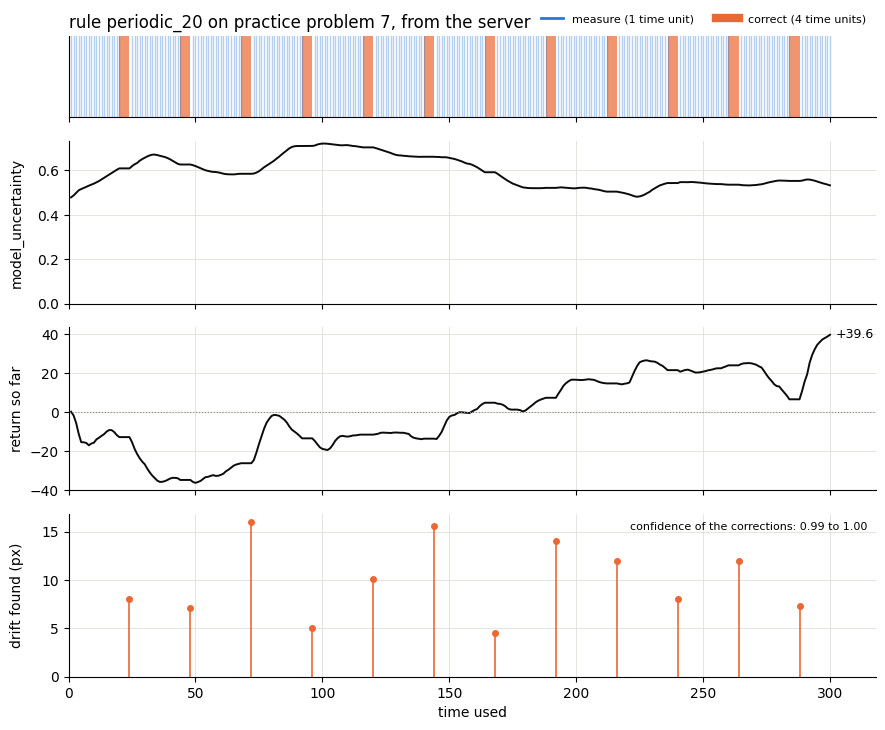

score on the server:     0.049
score on your computer:  0.049
biggest difference between a number from the server and the same number on your computer: 1.8e-05
(rounding only, it should be far below 0.001)


In [ ]:
import drift_client as sc

SERVER = "https://drift-server-production-4aed294d.up.railway.app"  # the address of the course server
server = sc.Server(SERVER)

env = server.make_env(seed=7)  # practice problem 7, played on the server
log = pd.DataFrame(play(env, BASELINES["periodic_20"]))  # the rows exactly as the server returned them
display(log.head())
plot_episode(log, "rule periodic_20 on practice problem 7, from the server")

local_log = pd.DataFrame(play(DriftEnv(seed=7), BASELINES["periodic_20"]))
print("score on the server:    ", round(env.final_metrics()["hidden_score"], 4))
print("score on your computer: ", round(evaluate(BASELINES["periodic_20"], [7])[0]["hidden_score"], 4))
numbers = log.select_dtypes("number").columns
worst = np.nanmax(np.abs(log[numbers].to_numpy(float) - local_log[numbers].to_numpy(float)))
print(f"biggest difference between a number from the server and the same number on your computer: {worst:.1e}")
print("(rounding only, it should be far below 0.001)")

Now the graded run. Before you start:

- Run the whole notebook from the top (Colab: Runtime > Restart and run all. Jupyter: Kernel > Restart & Run All). Then this cell runs last.
- The cell first tests your agent once on your computer to catch bugs. Then it runs your agent on 10 hidden problems. This takes about 6 minutes.
- You have 3 attempts. The cell prints your scores and a verification code. Do not change them.
- Your agent must not explore at random now. `train` already set `agent.training = False`.
- If the run stops half way, fix the problem and run the cell again. It continues where it stopped.
- If your teacher gave you a class code, write `class_code="..."` inside `run_test(...)`.
- Hand in the notebook with these outputs saved.

In [ ]:
my_name = "Surname Name"  # TODO: your surname and name

episodes = {}  # keeps what the server returned for each hidden problem
result = sc.run_test(server, agent.choose_action, name=my_name, record=episodes)

ValueError: set my_name to your own surname and name

### A hidden problem in detail (optional, not graded)

After the run you can plot what the server returned for any hidden problem. Change `which` (1 to 10).

In [ ]:
which = 1  # hidden problem, 1 to 10
if which in episodes:
    plot_episode(pd.DataFrame(episodes[which]), f"hidden problem {which}, from the server")
else:
    print("nothing was kept for this problem: it was finished in an earlier run")